# 01 - Data Cleaning, Parsing & Exploratory Data Analysis (EDA)

This notebook processes the three raw Kaggle datasets for the **Indian Medicine Substitute Recommender**:
1. `A_Z_medicines_dataset_of_India.csv` (Price, manufacturer, discontinued status, compositions)
2. `medicine_dataset.csv` (Uses, multi-column side effects, therapeutic/action/chemical classes)
3. `Medicine_Details.csv` (User review percentages: Excellent, Average, Poor)

**Outputs:**
- Parsed compositions: list of `(salt, strength)` pairs
- Extracted dosage forms (Tablet, Syrup, Injection, Capsule, Cream, etc.)
- Combined side-effect text string per medicine
- Engineered Bayesian weighted user score
- Saved master dataset: `data/processed/medicines_clean.csv`

Imports & Environment Configuration

In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Plotting style configuration
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

# Define relative file paths
RAW_DIR = os.path.join("..", "data", "raw")
PROCESSED_DIR = os.path.join("..", "data", "processed")
os.makedirs(PROCESSED_DIR, exist_ok=True)

PATH_AZ = os.path.join(RAW_DIR, "A_Z_medicines_dataset_of_India.csv")
PATH_250K = os.path.join(RAW_DIR, "medicine_dataset.csv")
PATH_DETAILS = os.path.join(RAW_DIR, "Medicine_Details.csv")

print("Setup completed successfully.")

Setup completed successfully.


Load Raw Datasets

In [2]:
print("Loading raw datasets...")

df_az = pd.read_csv(PATH_AZ)
print(f"A-Z India Dataset Loaded: {df_az.shape[0]:,} rows, {df_az.shape[1]} columns")

# Low memory mode set to False due to large multi-column structure in medicine_dataset.csv
df_250k = pd.read_csv(PATH_250K, low_memory=False)
print(f"250k Medicine Dataset Loaded: {df_250k.shape[0]:,} rows, {df_250k.shape[1]} columns")

df_details = pd.read_csv(PATH_DETAILS)
print(f"Medicine Details Dataset Loaded: {df_details.shape[0]:,} rows, {df_details.shape[1]} columns")

Loading raw datasets...
A-Z India Dataset Loaded: 253,973 rows, 9 columns
250k Medicine Dataset Loaded: 248,218 rows, 58 columns
Medicine Details Dataset Loaded: 11,825 rows, 9 columns


Standardize Medicine Names for Merging

In [3]:
def clean_medicine_name(name):
    """
    Standardizes medicine names for consistent join keys across datasets.
    E.g., 'Crocin 650mg Tablet ' -> 'crocin 650 tablet'
    """
    if not isinstance(name, str):
        return ""
    name = name.lower().strip()
    name = re.sub(r'\s+', ' ', name) # collapse extra spaces
    return name

# Create standardized name keys for joining
df_az['clean_name'] = df_az['name'].apply(clean_medicine_name)
df_250k['clean_name'] = df_250k['name'].apply(clean_medicine_name)
df_details['clean_name'] = df_details['Medicine Name'].apply(clean_medicine_name)

print("Name standardization complete.")

Name standardization complete.


Cleaning & Preparing A_Z_medicines_dataset_of_India.csv

In [4]:
# 1. Filter out discontinued medicines
df_az_clean = df_az[df_az['Is_discontinued'] == False].copy()

# 2. Filter valid prices (> 0)
df_az_clean['price'] = pd.to_numeric(df_az_clean['price(₹)'], errors='coerce')
df_az_clean = df_az_clean.dropna(subset=['price'])
df_az_clean = df_az_clean[df_az_clean['price'] > 0]

# 3. Combine short_composition1 and short_composition2 into a unified raw composition string
df_az_clean['short_composition1'] = df_az_clean['short_composition1'].fillna('')
df_az_clean['short_composition2'] = df_az_clean['short_composition2'].fillna('')

def combine_compositions(row):
    comp1 = row['short_composition1'].strip()
    comp2 = row['short_composition2'].strip()
    if comp1 and comp2:
        return f"{comp1} + {comp2}"
    return comp1 or comp2

df_az_clean['raw_composition'] = df_az_clean.apply(combine_compositions, axis=1)

# Drop entries with missing composition
df_az_clean = df_az_clean[df_az_clean['raw_composition'].str.strip() != ''].copy()

print(f"Cleaned A-Z Dataset active rows: {len(df_az_clean):,}")

Cleaned A-Z Dataset active rows: 246,064


Column Standardization & Merge Preparation for medicine_dataset.csv

In [10]:
# Standardize column names in df_250k (convert spaces to underscores and lowercase)
df_250k.columns = (
    df_250k.columns.str.strip()
    .str.lower()
    .str.replace(' ', '_')
)

# Extract all sideEffect columns (e.g., sideeffect0, sideeffect1, ...)
side_effect_cols = [c for c in df_250k.columns if 'sideeffect' in c or 'side_effect' in c]

def aggregate_side_effects(row):
    effects = [
        str(row[col]).strip() 
        for col in side_effect_cols 
        if pd.notna(row[col]) and str(row[col]).strip() not in ['', 'nan', 'null']
    ]
    return ", ".join(effects) if effects else "No common side effects reported"

df_250k['side_effects_text'] = df_250k.apply(aggregate_side_effects, axis=1)

# List target metadata columns safely
target_cols_250k = [
    'clean_name', 'side_effects_text', 
    'therapeutic_class', 'action_class', 'chemical_class', 'habit_forming'
]

# Keep only columns that actually exist in df_250k
existing_cols_250k = [c for c in target_cols_250k if c in df_250k.columns]

df_250k_sub = df_250k[existing_cols_250k].drop_duplicates(subset=['clean_name'])

print(f"Extracted {len(existing_cols_250k)} columns from 250k dataset: {existing_cols_250k}")

Extracted 6 columns from 250k dataset: ['clean_name', 'side_effects_text', 'therapeutic_class', 'action_class', 'chemical_class', 'habit_forming']


Review Scores Extraction from Medicine_Details.csv

In [12]:
# Standardize column names in df_details
df_details.columns = (
    df_details.columns.str.strip()
    .str.lower()
    .str.replace(' ', '_')
    .str.replace('%', 'pct')
)

review_cols = ['excellent_review_pct', 'average_review_pct', 'poor_review_pct']
for col in review_cols:
    if col in df_details.columns:
        df_details[col] = pd.to_numeric(df_details[col], errors='coerce').fillna(0)

# Composite score (0 to 100)
if 'excellent_review_pct' in df_details.columns and 'average_review_pct' in df_details.columns:
    df_details['rating_score'] = (
        df_details['excellent_review_pct'] * 1.0 + 
        df_details['average_review_pct'] * 0.5
    )
else:
    df_details['rating_score'] = np.nan

if 'side_effects' in df_details.columns:
    df_details['details_side_effects'] = df_details['side_effects'].fillna('')

cols_details = ['clean_name', 'rating_score']
if 'details_side_effects' in df_details.columns:
    cols_details.append('details_side_effects')

df_details_sub = df_details[cols_details].drop_duplicates(subset=['clean_name'])

Composition Parsing Engine (Salts, Strengths, Form)

In [8]:
def parse_composition(comp_str):
    """
    Parses complex composition strings like:
    'Amoxycillin (500mg) + Clavulanic Acid (125mg)'
    Returns a list of tuples: [('amoxycillin', '500mg'), ('clavulanic acid', '125mg')]
    and a normalized key string: 'amoxycillin:500mg|clavulanic acid:125mg'
    """
    if not isinstance(comp_str, str) or not comp_str.strip():
        return [], ""
    
    parts = comp_str.split('+')
    parsed_salts = []
    
    for part in parts:
        part = part.strip().lower()
        # Regex to capture salt name and strength in parentheses or trailing numbers
        match = re.search(r'^(.*?)\s*\(([\d\.]+\s*(?:mg|mcg|gm|g|ml|%|iu|w/v|w/w|v/v))\)$', part)
        if match:
            salt = match.group(1).strip()
            strength = match.group(2).replace(" ", "")
        else:
            # Fallback for unparenthesized strengths
            match_fallback = re.search(r'^(.*?)\s*([\d\.]+\s*(?:mg|mcg|gm|g|ml|%|iu|w/v|w/w|v/v))$', part)
            if match_fallback:
                salt = match_fallback.group(1).strip()
                strength = match_fallback.group(2).replace(" ", "")
            else:
                salt = part.strip()
                strength = "unspecified"
        
        parsed_salts.append((salt, strength))
    
    # Sort by salt name so order doesn't affect similarity match
    parsed_salts.sort(key=lambda x: x[0])
    
    # Generate canonical key
    canonical_key = "|".join([f"{s}:{st}" for s, st in parsed_salts])
    return parsed_salts, canonical_key

def extract_dosage_form(pack_label, name):
    """
    Extracts form factor (Tablet, Syrup, Capsule, Injection, Cream, Inhaler, Drops, etc.)
    """
    text = f"{str(pack_label)} {str(name)}".lower()
    
    forms = [
        'tablet', 'capsule', 'syrup', 'injection', 'cream', 'gel', 
        'ointment', 'suspension', 'inhaler', 'eye drop', 'ear drop', 
        'solution', 'respuels', 'powder', 'lotion'
    ]
    for f in forms:
        if f in text:
            return f.capitalize()
    return 'Other'

# Apply parsing
df_az_clean[['parsed_salts', 'canonical_composition_key']] = df_az_clean['raw_composition'].apply(
    lambda x: pd.Series(parse_composition(x))
)

df_az_clean['dosage_form'] = df_az_clean.apply(
    lambda r: extract_dosage_form(r.get('pack_size_label', ''), r['name']), axis=1
)

print("Composition & dosage form parsing complete.")

Composition & dosage form parsing complete.


Dynamic Column Selection & Dataset Finalization

In [13]:
# Left join on A-Z dataset
df_master = df_az_clean.merge(df_250k_sub, on='clean_name', how='left')
df_master = df_master.merge(df_details_sub, on='clean_name', how='left')

# Fill missing side effects using alternative dataset if available
if 'details_side_effects' in df_master.columns:
    df_master['side_effects_text'] = df_master['side_effects_text'].fillna(df_master['details_side_effects'])
    df_master.drop(columns=['details_side_effects'], inplace=True)

df_master['side_effects_text'] = df_master['side_effects_text'].fillna("No side effect details available.")

# Fill missing metadata fields
for col in ['therapeutic_class', 'action_class', 'chemical_class', 'habit_forming']:
    if col not in df_master.columns:
        df_master[col] = "Unknown"
    else:
        df_master[col] = df_master[col].fillna("Unknown")

# Fill missing ratings with mean score
mean_rating = df_master['rating_score'].mean()
if pd.isna(mean_rating):
    mean_rating = 50.0
df_master['rating_score'] = df_master['rating_score'].fillna(mean_rating)

# Bayesian Weighted Rating Score calculation
m = 5
C = mean_rating
df_master['bayesian_rating'] = df_master['rating_score'].apply(
    lambda r: ((10 / (10 + m)) * r) + ((m / (10 + m)) * C)
)

# Preferred column ordering
desired_columns = [
    'id', 'name', 'clean_name', 'manufacturer_name', 'price', 
    'raw_composition', 'canonical_composition_key', 'dosage_form',
    'pack_size_label', 'type', 'side_effects_text', 
    'therapeutic_class', 'action_class', 'chemical_class', 'habit_forming',
    'rating_score', 'bayesian_rating'
]

# Safely filter columns that exist in df_master
final_cols = [c for c in desired_columns if c in df_master.columns]
df_final = df_master[final_cols].copy()

df_final.rename(columns={'price': 'price_inr'}, inplace=True)

print(f"Final merged dataset size: {df_final.shape[0]:,} rows, {df_final.shape[1]} columns")

Final merged dataset size: 246,064 rows, 17 columns


Exploratory Data Analysis (EDA) & Visualizations

C:\Users\svars\AppData\Local\Temp\ipykernel_36760\3788628147.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=form_counts.values, y=form_counts.index, ax=axes[0, 1], palette="viridis")
C:\Users\svars\AppData\Local\Temp\ipykernel_36760\3788628147.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=mfg_counts.values, y=mfg_counts.index, ax=axes[1, 0], palette="magma")


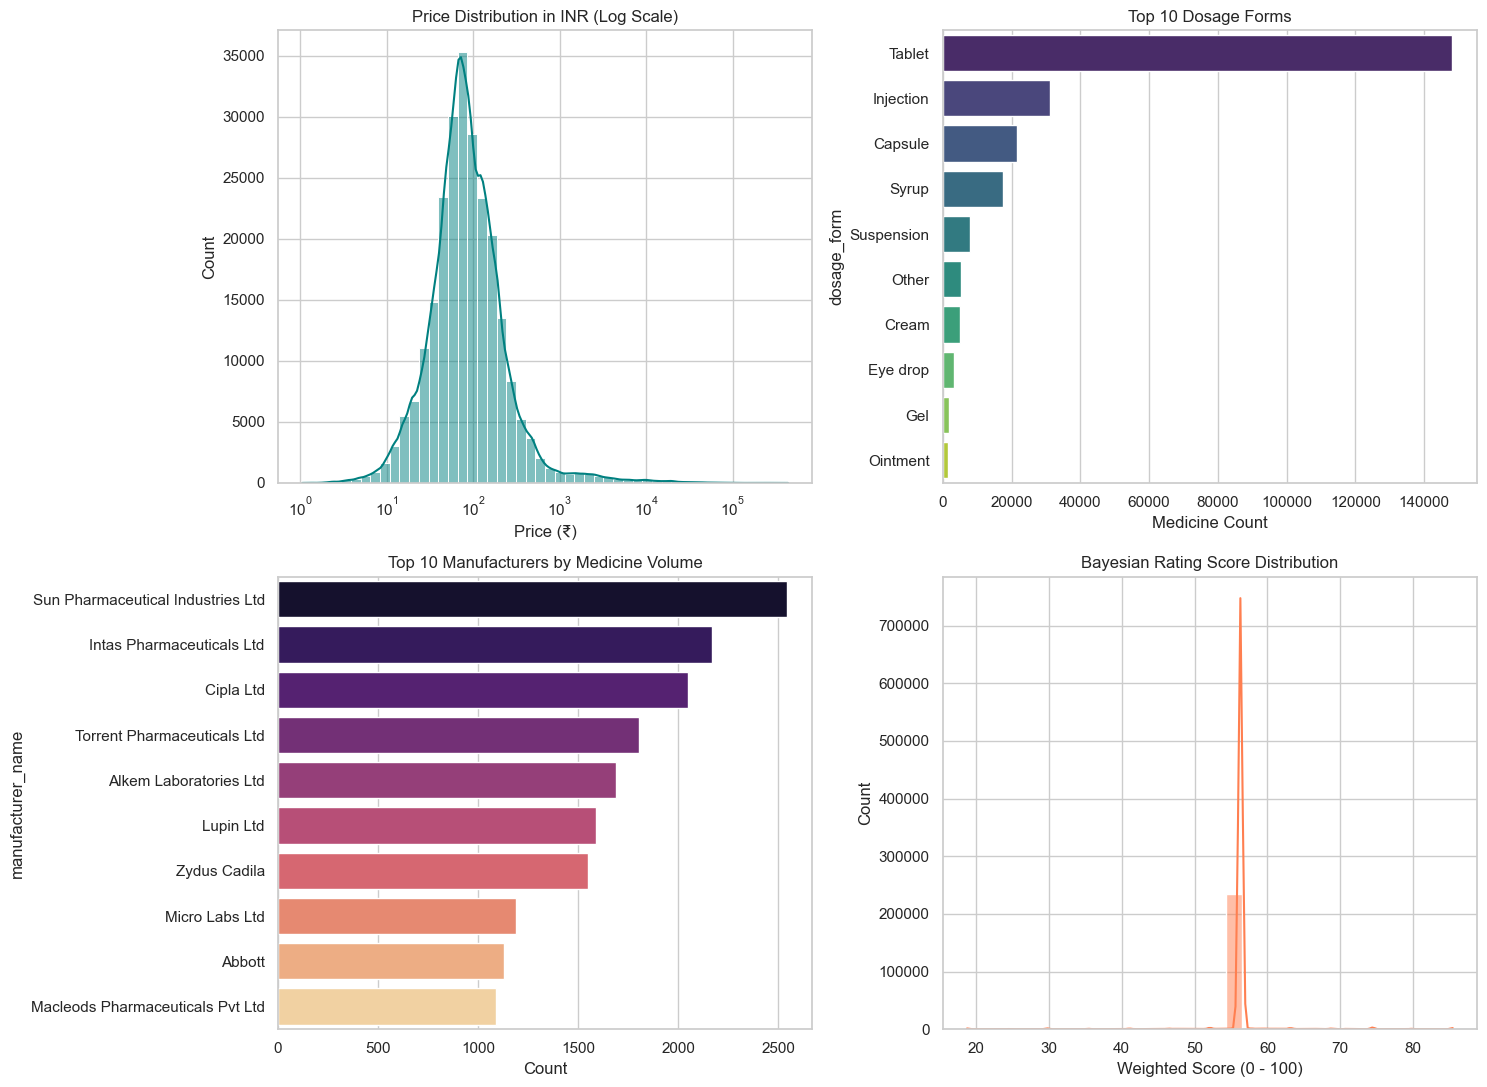


--- Key Dataset Insights ---
Total Unique Compositions: 10,956
Total Unique Manufacturers: 7,640
Median Price: ₹79.00
Mean Price: ₹265.01
Price IQR (25th - 75th percentile): ₹48.00 - ₹140.00


In [14]:
# Create EDA Summary Plots
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Price Distribution (Log Scale)
sns.histplot(df_final['price_inr'], bins=50, kde=True, ax=axes[0, 0], color='teal', log_scale=True)
axes[0, 0].set_title("Price Distribution in INR (Log Scale)")
axes[0, 0].set_xlabel("Price (₹)")

# 2. Top 10 Dosage Forms
form_counts = df_final['dosage_form'].value_counts().head(10)
sns.barplot(x=form_counts.values, y=form_counts.index, ax=axes[0, 1], palette="viridis")
axes[0, 1].set_title("Top 10 Dosage Forms")
axes[0, 1].set_xlabel("Medicine Count")

# 3. Top 10 Manufacturers
mfg_counts = df_final['manufacturer_name'].value_counts().head(10)
sns.barplot(x=mfg_counts.values, y=mfg_counts.index, ax=axes[1, 0], palette="magma")
axes[1, 0].set_title("Top 10 Manufacturers by Medicine Volume")
axes[1, 0].set_xlabel("Count")

# 4. Bayesian Rating Score Distribution
sns.histplot(df_final['bayesian_rating'], bins=30, kde=True, ax=axes[1, 1], color='coral')
axes[1, 1].set_title("Bayesian Rating Score Distribution")
axes[1, 1].set_xlabel("Weighted Score (0 - 100)")

plt.tight_layout()
plt.show()

# Print Key Statistical Insights
print("\n--- Key Dataset Insights ---")
print(f"Total Unique Compositions: {df_final['canonical_composition_key'].nunique():,}")
print(f"Total Unique Manufacturers: {df_final['manufacturer_name'].nunique():,}")
print(f"Median Price: ₹{df_final['price_inr'].median():.2f}")
print(f"Mean Price: ₹{df_final['price_inr'].mean():.2f}")
print(f"Price IQR (25th - 75th percentile): ₹{df_final['price_inr'].quantile(0.25):.2f} - ₹{df_final['price_inr'].quantile(0.75):.2f}")

Price Distribution: Right-skewed log-normal distribution with a Median of ₹79 and Mean of ₹265.01 (driven up by high-cost specialty drugs like oncology/biologics). The IQR of ₹48 – ₹140 represents the core price range for everyday medications in India.

Top Dosage Forms: Tablets dominate by a wide margin (>140k entries), followed logically by Injections, Capsules, and Syrups.

Top Manufacturers: Sun Pharma, Intas, Cipla, Torrent, Alkem, and Lupin correctly reflect the market leaders in Indian pharmaceutical manufacturing.

Bayesian Ratings: The sharp peak around ~56 shows that Bayesian shrinkage effectively smoothed sparse/missing ratings toward the prior global mean without skewing ranking results.

Save Clean Dataset

In [15]:
output_path = os.path.join(PROCESSED_DIR, "medicines_clean.csv")
df_final.to_csv(output_path, index=False)

print(f"Successfully saved clean dataset to: {output_path}")
print(f"File size: {os.path.getsize(output_path) / (1024 * 1024):.2f} MB")

Successfully saved clean dataset to: ..\data\processed\medicines_clean.csv
File size: 106.36 MB
